# Baseline Model 2: 1D CNN Encoder-Decoder

## Purpose
A **simple CNN-based baseline** without skip connections or complex architecture.

This establishes the **lower bound** for deep learning approaches and shows
that more complex architectures (U-Net, GANs) are necessary.

## Architecture
- **Encoder**: Stack of Conv1D layers with stride=2 for downsampling
- **Bottleneck**: Compressed representation
- **Decoder**: Stack of ConvTranspose1D layers for upsampling
- **No skip connections** (unlike U-Net)

## Expected Outcome
Lower performance than U-Net due to:
- Loss of fine-grained information through bottleneck
- No skip connections to preserve high-frequency details

## 1. Setup and Imports

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Run shared config notebook to get all utilities
%run "/content/drive/MyDrive/Paper1_ECG_Reconstruction/notebooks/00_SHARED_CONFIG.ipynb"

# Verify DEVICE was imported correctly (fallback if %run has scoping issues)
try:
    print(f"DEVICE successfully imported: {DEVICE}")
except NameError:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"DEVICE defined locally: {DEVICE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.9.0+cu126
CUDA: True
GPU: NVIDIA A100-SXM4-40GB (42.5 GB)
Recommended batch size: 32
Dependencies installed.
Device: cuda
PAPER 1: ECG RECONSTRUCTION - CONFIGURATION

Data:
  Chunks: /content/drive/MyDrive/October Thesis Dataset/Refine-Chunked
  Signal: 64000 samples (8.0s)

Training:
  Batch size: 16
  Epochs: 100
  Learning rate: 5e-05

Output:
  Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results
  Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints
Preprocessing functions loaded.
  - ensure_positive_polarity()
  - normalize_signal()
  - preprocess_ecg_pcg()
Augmentation functions loaded.
Dataset class loaded.
Metrics functions loaded:
  - calc_psnr(), calc_snr(), calc_correlation(), calc_ssim()
  - calc_mae(), calc_rmse()
  - calc_r_peak_error(), calc_qrs_width_error()
  - calc_all_metrics()
  - convert_to_se

In [3]:
# Model-specific configuration
MODEL_CONFIG = {
    'model_name': 'CNN_EncoderDecoder',
    'batch_size': 32,
    'learning_rate': 1e-4,
    'epochs': 100,
    'patience': 15,
    'loss_type': 'L1',
    'base_filters': 64,
}

# Create model-specific directories
model_save_dir = os.path.join(CONFIG['checkpoints_dir'], MODEL_CONFIG['model_name'])
model_results_dir = os.path.join(CONFIG['results_dir'], MODEL_CONFIG['model_name'])
os.makedirs(model_save_dir, exist_ok=True)
os.makedirs(model_results_dir, exist_ok=True)

print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Checkpoints: {model_save_dir}")
print(f"Results: {model_results_dir}")

Model: CNN_EncoderDecoder
Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/CNN_EncoderDecoder
Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/CNN_EncoderDecoder


## 2. CNN Encoder-Decoder Architecture

Simple architecture without skip connections.

In [4]:
class ConvBlock(nn.Module):
    """Convolutional block: Conv1D -> BatchNorm -> LeakyReLU."""
    def __init__(self, in_channels, out_channels, kernel_size=4, stride=2, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm1d(out_channels),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DeconvBlock(nn.Module):
    """Deconvolutional block: ConvTranspose1D -> BatchNorm -> ReLU."""
    def __init__(self, in_channels, out_channels, kernel_size=4, stride=2, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.ConvTranspose1d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class CNNEncoderDecoder(nn.Module):
    """
    Simple 1D CNN Encoder-Decoder for PCG to ECG translation.

    Architecture:
    - Encoder: 1 -> 64 -> 128 -> 256 -> 512 -> 512 (bottleneck)
    - Decoder: 512 -> 512 -> 256 -> 128 -> 64 -> 1

    No skip connections - information must pass through bottleneck.
    """
    def __init__(self, in_channels=1, out_channels=1, base_filters=64):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(in_channels, base_filters)           # 64000 -> 32000, 64
        self.enc2 = ConvBlock(base_filters, base_filters * 2)      # 32000 -> 16000, 128
        self.enc3 = ConvBlock(base_filters * 2, base_filters * 4)  # 16000 -> 8000, 256
        self.enc4 = ConvBlock(base_filters * 4, base_filters * 8)  # 8000 -> 4000, 512
        self.enc5 = ConvBlock(base_filters * 8, base_filters * 8)  # 4000 -> 2000, 512
        self.enc6 = ConvBlock(base_filters * 8, base_filters * 8)  # 2000 -> 1000, 512
        self.enc7 = ConvBlock(base_filters * 8, base_filters * 8)  # 1000 -> 500, 512
        self.enc8 = ConvBlock(base_filters * 8, base_filters * 8)  # 500 -> 250, 512 (bottleneck)

        # Decoder (NO skip connections)
        self.dec1 = DeconvBlock(base_filters * 8, base_filters * 8)  # 250 -> 500, 512
        self.dec2 = DeconvBlock(base_filters * 8, base_filters * 8)  # 500 -> 1000, 512
        self.dec3 = DeconvBlock(base_filters * 8, base_filters * 8)  # 1000 -> 2000, 512
        self.dec4 = DeconvBlock(base_filters * 8, base_filters * 8)  # 2000 -> 4000, 512
        self.dec5 = DeconvBlock(base_filters * 8, base_filters * 4)  # 4000 -> 8000, 256
        self.dec6 = DeconvBlock(base_filters * 4, base_filters * 2)  # 8000 -> 16000, 128
        self.dec7 = DeconvBlock(base_filters * 2, base_filters)      # 16000 -> 32000, 64

        # Final output layer - NO TANH
        self.final = nn.ConvTranspose1d(base_filters, out_channels, kernel_size=4, stride=2, padding=1)

    def forward(self, x):
        input_size = x.size(2)

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)
        e6 = self.enc6(e5)
        e7 = self.enc7(e6)
        bottleneck = self.enc8(e7)

        # Decoder (no skip connections - information must pass through bottleneck)
        d1 = self.dec1(bottleneck)
        d2 = self.dec2(d1)
        d3 = self.dec3(d2)
        d4 = self.dec4(d3)
        d5 = self.dec5(d4)
        d6 = self.dec6(d5)
        d7 = self.dec7(d6)

        output = self.final(d7)

        # Handle size mismatch
        if output.size(2) != input_size:
            diff = input_size - output.size(2)
            output = F.pad(output, (diff // 2, diff - diff // 2))

        return output

In [5]:
# Initialize model
model = CNNEncoderDecoder(
    in_channels=1,
    out_channels=1,
    base_filters=MODEL_CONFIG['base_filters']
).to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Test forward pass
test_input = torch.randn(2, 1, CONFIG['signal_length']).to(DEVICE)
test_output = model(test_input)
print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")

Total parameters: 9,776,385
Trainable parameters: 9,776,385
Input shape: torch.Size([2, 1, 64000])
Output shape: torch.Size([2, 1, 64000])


## 3. Load Data

In [6]:
# Load datasets using shared utilities
train_loader, val_loader, test_loader, train_dataset = create_dataloaders(CONFIG)

# Quick verification
sample_batch = next(iter(train_loader))
print(f"\nBatch verification:")
print(f"  PCG shape: {sample_batch['pcg'].shape}")
print(f"  ECG shape: {sample_batch['ecg'].shape}")

Loading datasets...
TRAIN: 4059 chunks from 14 subjects
  Scenarios: Rest=1134, Exercise=2925, Other=0
VAL: 681 chunks from 3 subjects
  Scenarios: Rest=231, Exercise=450, Other=0
TEST: 453 chunks from 3 subjects
  Scenarios: Rest=3, Exercise=450, Other=0

Dataloaders created:
  Train: 253 batches
  Val: 43 batches
  Test: 29 batches

Batch verification:
  PCG shape: torch.Size([16, 1, 64000])
  ECG shape: torch.Size([16, 1, 64000])


In [7]:
# Dataloaders already created
print(f"Train: {len(train_loader)} batches, Val: {len(val_loader)} batches, Test: {len(test_loader)} batches")

Train: 253 batches, Val: 43 batches, Test: 29 batches


## 4. Training Setup

In [8]:
# Loss, optimizer, scheduler
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=MODEL_CONFIG['learning_rate'], betas=(0.5, 0.999))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MODEL_CONFIG['epochs'], eta_min=1e-6)
early_stopping = EarlyStopping(patience=MODEL_CONFIG['patience'], min_delta=0.001)

## 5. Training Loop

In [9]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    for batch in train_loader:
        pcg = batch['pcg'].to(device)
        ecg = batch['ecg'].to(device)
        optimizer.zero_grad()
        ecg_pred = model(pcg)
        loss = criterion(ecg_pred, ecg)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip'])
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)


def validate_epoch(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_metrics = []
    with torch.no_grad():
        for batch in val_loader:
            pcg = batch['pcg'].to(device)
            ecg = batch['ecg'].to(device)
            ecg_pred = model(pcg)
            loss = criterion(ecg_pred, ecg)
            total_loss += loss.item()
            for i in range(ecg.size(0)):
                pred = ecg_pred[i, 0].cpu().numpy()
                true = ecg[i, 0].cpu().numpy()
                all_metrics.append(calc_all_metrics(pred, true))

    avg_metrics = {}
    for key in all_metrics[0].keys():
        values = [m[key] for m in all_metrics if m[key] is not None]
        avg_metrics[key] = np.mean(values) if values else None
    return total_loss / len(val_loader), avg_metrics

In [10]:
# Training history
history = {'train_loss': [], 'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'val_correlation': [], 'learning_rate': []}
best_val_loss = float('inf')
best_epoch = 0

print(f"Starting training: {MODEL_CONFIG['model_name']}")
print(f"Epochs: {MODEL_CONFIG['epochs']}, Batch size: {MODEL_CONFIG['batch_size']}, Device: {DEVICE}")
print("=" * 60)

Starting training: CNN_EncoderDecoder
Epochs: 100, Batch size: 32, Device: cuda


In [14]:
def calc_all_metrics(real_ecg, fake_ecg, include_expensive=True):
    """
    Calculate all metrics for signals.

    Args:
        real_ecg: Tensor/array - can be [T], [1, T], [B, T], or [B, 1, T]
        fake_ecg: Same shape as real_ecg
        include_expensive: Whether to calculate R-peak and QRS metrics

    Returns:
        dict: All metric values
    """
    if torch.is_tensor(real_ecg):
        real_ecg = real_ecg.cpu().numpy()
    if torch.is_tensor(fake_ecg):
        fake_ecg = fake_ecg.cpu().numpy()

    # Handle different input shapes
    if real_ecg.ndim == 1:
        # Single 1D sample [T] - just compute metrics directly
        result = {
            'psnr': calc_psnr(real_ecg, fake_ecg),
            'snr': calc_snr(real_ecg, fake_ecg),
            'correlation': calc_correlation(real_ecg, fake_ecg),
            'ssim': calc_ssim(real_ecg, fake_ecg),
            'mae': calc_mae(real_ecg, fake_ecg),
            'rmse': calc_rmse(real_ecg, fake_ecg),
            'out_min': float(fake_ecg.min()),
            'out_max': float(fake_ecg.max()),
        }
        if include_expensive:
            result['r_peak_error'] = calc_r_peak_error(real_ecg, fake_ecg)
            result['qrs_width_error'] = calc_qrs_width_error(real_ecg, fake_ecg)
        return result

    if real_ecg.ndim == 3:
        real_ecg = real_ecg.squeeze(1)
        fake_ecg = fake_ecg.squeeze(1)

    # Now should be [B, T]
    if real_ecg.ndim == 2 and real_ecg.shape[0] == 1:
        # Single sample with batch dim [1, T]
        real_ecg = real_ecg[0]
        fake_ecg = fake_ecg[0]
        result = {
            'psnr': calc_psnr(real_ecg, fake_ecg),
            'snr': calc_snr(real_ecg, fake_ecg),
            'correlation': calc_correlation(real_ecg, fake_ecg),
            'ssim': calc_ssim(real_ecg, fake_ecg),
            'mae': calc_mae(real_ecg, fake_ecg),
            'rmse': calc_rmse(real_ecg, fake_ecg),
            'out_min': float(fake_ecg.min()),
            'out_max': float(fake_ecg.max()),
        }
        if include_expensive:
            result['r_peak_error'] = calc_r_peak_error(real_ecg, fake_ecg)
            result['qrs_width_error'] = calc_qrs_width_error(real_ecg, fake_ecg)
        return result

    # Batch of samples [B, T]
    batch_size = real_ecg.shape[0]

    metrics = {
        'psnr': [], 'snr': [], 'correlation': [], 'ssim': [],
        'mae': [], 'rmse': []
    }
    if include_expensive:
        metrics['r_peak_error'] = []
        metrics['qrs_width_error'] = []

    for i in range(batch_size):
        real = real_ecg[i]
        fake = fake_ecg[i]

        metrics['psnr'].append(calc_psnr(real, fake))
        metrics['snr'].append(calc_snr(real, fake))
        metrics['correlation'].append(calc_correlation(real, fake))
        metrics['ssim'].append(calc_ssim(real, fake))
        metrics['mae'].append(calc_mae(real, fake))
        metrics['rmse'].append(calc_rmse(real, fake))

        if include_expensive:
            r_err = calc_r_peak_error(real, fake)
            qrs_err = calc_qrs_width_error(real, fake)
            if r_err is not None and not np.isnan(r_err):
                metrics['r_peak_error'].append(r_err)
            if qrs_err is not None and not np.isnan(qrs_err):
                metrics['qrs_width_error'].append(qrs_err)

    # Average over batch
    result = {k: float(np.mean(v)) if v else 0.0 for k, v in metrics.items()}
    result['out_min'] = float(fake_ecg.min())
    result['out_max'] = float(fake_ecg.max())

    return result

In [15]:
import numpy as np
from scipy.stats import pearsonr

def calc_correlation(real, fake):
    """Calculates Pearson correlation between two 1D numpy arrays."""
    # Ensure inputs are 1D arrays
    real = np.asarray(real).flatten()
    fake = np.asarray(fake).flatten()

    if len(real) != len(fake):
        # This should ideally not happen if inputs are well-formed 1D signals
        return None

    # Pearsonr returns (correlation_coefficient, p_value)
    try:
        corr, _ = pearsonr(real, fake)
        return float(corr) if not np.isnan(corr) else None
    except Exception:
        # Return None if correlation cannot be computed (e.g., constant signal)
        return None

print("Corrected `calc_correlation` function defined.")


Corrected `calc_correlation` function defined.


In [16]:
# Main training loop
for epoch in range(MODEL_CONFIG['epochs']):
    # Set epoch for progressive augmentation
    train_dataset.set_epoch(epoch + 1)

    train_loss = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_metrics = validate_epoch(model, val_loader, criterion, DEVICE)

    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_psnr'].append(val_metrics['psnr'])
    history['val_ssim'].append(val_metrics['ssim'])
    history['val_correlation'].append(val_metrics['correlation'])
    history['learning_rate'].append(current_lr)

    print(f"Epoch [{epoch+1}/{MODEL_CONFIG['epochs']}] "
          f"Train: {train_loss:.4f} | Val: {val_loss:.4f} | "
          f"PSNR: {val_metrics['psnr']:.2f} | SSIM: {val_metrics['ssim']:.4f} | "
          f"Corr: {val_metrics['correlation']:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        save_checkpoint(model, optimizer, epoch, val_loss, os.path.join(model_save_dir, 'best_model.pt'), MODEL_CONFIG['model_name'])
        print(f"  -> New best model saved!")

    if early_stopping(val_loss):
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

    if (epoch + 1) % 10 == 0:
        save_checkpoint(model, optimizer, epoch, val_loss, os.path.join(model_save_dir, f'checkpoint_epoch_{epoch+1}.pt'), MODEL_CONFIG['model_name'])

print(f"\nTraining completed! Best epoch: {best_epoch}, Best val loss: {best_val_loss:.4f}")

Epoch [1/100] Train: 0.6581 | Val: 0.6521 | PSNR: 8.62 | SSIM: 0.6396 | Corr: 0.1852
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/CNN_EncoderDecoder/best_model.pt
  -> New best model saved!
Epoch [2/100] Train: 0.6389 | Val: 0.6772 | PSNR: 7.55 | SSIM: 0.7440 | Corr: 0.1487
Epoch [3/100] Train: 0.6240 | Val: 0.6603 | PSNR: 7.50 | SSIM: 0.7857 | Corr: 0.1407
Epoch [4/100] Train: 0.6108 | Val: 0.6615 | PSNR: 8.54 | SSIM: 0.8121 | Corr: 0.1354
Epoch [5/100] Train: 0.5994 | Val: 0.6807 | PSNR: 6.78 | SSIM: 0.8134 | Corr: 0.0839
Epoch [6/100] Train: 0.5919 | Val: 0.6757 | PSNR: 8.27 | SSIM: 0.8309 | Corr: 0.0856
Epoch [7/100] Train: 0.5848 | Val: 0.6903 | PSNR: 7.75 | SSIM: 0.8124 | Corr: 0.0558
Epoch [8/100] Train: 0.5762 | Val: 0.7128 | PSNR: 7.77 | SSIM: 0.8369 | Corr: 0.0669
Epoch [9/100] Train: 0.5713 | Val: 0.7031 | PSNR: 8.52 | SSIM: 0.8594 | Corr: 0.0646
Epoch [10/100] Train: 0.5671 | Val: 0.6753 | PSNR: 9.00 | SSIM: 0.8314 | Corr: 0.0509
Checkpoint

In [17]:
# Save training history
history_path = os.path.join(model_results_dir, 'training_history.json')
with open(history_path, 'w') as f:
    json.dump(convert_to_serializable(history), f, indent=2)
print(f"Training history saved to: {history_path}")

Training history saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/CNN_EncoderDecoder/training_history.json


## 6. Plot Training Curves

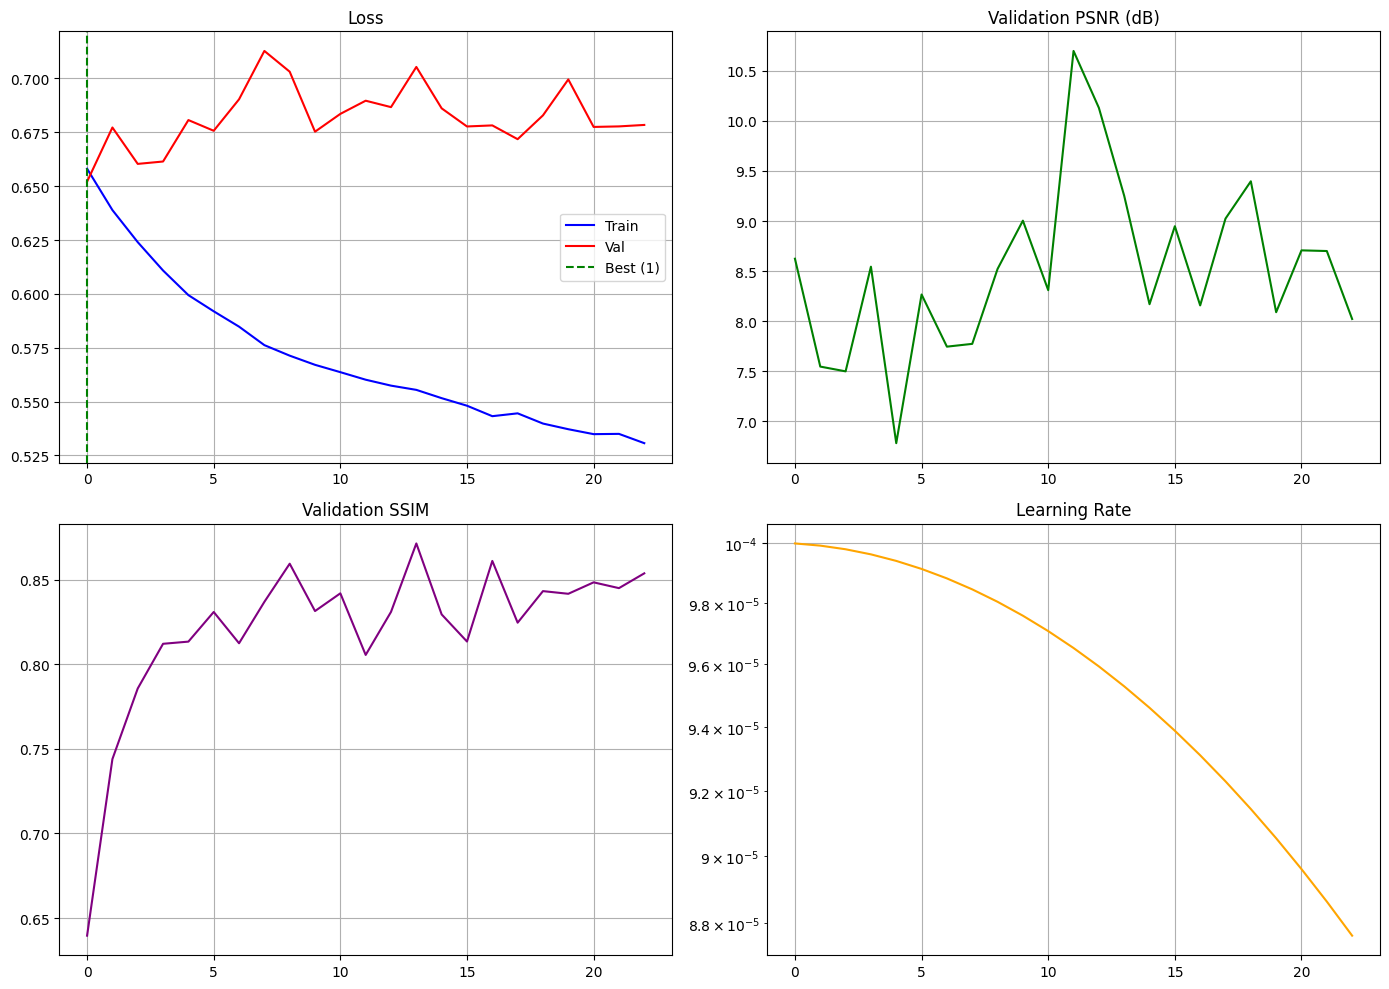

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history['train_loss'], label='Train', color='blue')
axes[0, 0].plot(history['val_loss'], label='Val', color='red')
axes[0, 0].axvline(x=best_epoch-1, color='green', linestyle='--', label=f'Best ({best_epoch})')
axes[0, 0].set_title('Loss'); axes[0, 0].legend(); axes[0, 0].grid(True)

axes[0, 1].plot(history['val_psnr'], color='green')
axes[0, 1].set_title('Validation PSNR (dB)'); axes[0, 1].grid(True)

axes[1, 0].plot(history['val_ssim'], color='purple')
axes[1, 0].set_title('Validation SSIM'); axes[1, 0].grid(True)

axes[1, 1].plot(history['learning_rate'], color='orange')
axes[1, 1].set_title('Learning Rate'); axes[1, 1].set_yscale('log'); axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(model_results_dir, 'training_curves.png'), dpi=150)
plt.show()

## 7. Test Evaluation

In [19]:
# Load best model
checkpoint = torch.load(os.path.join(model_save_dir, 'best_model.pt'), weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch'] + 1}")

Loaded best model from epoch 1


In [20]:
# Evaluate on test set
model.eval()
test_metrics = []
test_predictions, test_targets, test_inputs = [], [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating'):
        pcg = batch['pcg'].to(DEVICE)
        ecg = batch['ecg'].to(DEVICE)
        ecg_pred = model(pcg)

        test_predictions.append(ecg_pred.cpu().numpy())
        test_targets.append(ecg.cpu().numpy())
        test_inputs.append(pcg.cpu().numpy())

        for i in range(ecg.size(0)):
            test_metrics.append(calc_all_metrics(ecg_pred[i, 0].cpu().numpy(), ecg[i, 0].cpu().numpy()))

test_predictions = np.concatenate(test_predictions, axis=0)
test_targets = np.concatenate(test_targets, axis=0)
test_inputs = np.concatenate(test_inputs, axis=0)
print(f"Test samples: {len(test_metrics)}")

Evaluating:   0%|          | 0/29 [00:00<?, ?it/s]

Test samples: 453


In [21]:
# Calculate summary statistics
summary_stats = {}
for key in test_metrics[0].keys():
    values = [m[key] for m in test_metrics if m[key] is not None]
    if values:
        summary_stats[key] = {
            'mean': float(np.mean(values)), 'std': float(np.std(values)),
            'min': float(np.min(values)), 'max': float(np.max(values)), 'median': float(np.median(values))
        }

print("\n" + "=" * 60)
print(f"TEST RESULTS: {MODEL_CONFIG['model_name']}")
print("=" * 60)
print(f"{'Metric':<20} {'Mean':>10} {'Std':>10} {'Min':>10} {'Max':>10}")
print("-" * 60)
for key, stats in summary_stats.items():
    print(f"{key:<20} {stats['mean']:>10.4f} {stats['std']:>10.4f} {stats['min']:>10.4f} {stats['max']:>10.4f}")
print("=" * 60)


TEST RESULTS: CNN_EncoderDecoder
Metric                     Mean        Std        Min        Max
------------------------------------------------------------
psnr                    14.8029     4.6478     2.7456    24.8043
snr                     -4.8616     4.7744   -14.9506     3.2113
correlation              0.3701     0.2807    -0.5764     0.7975
ssim                     0.5707     0.1125     0.2707     0.8408
mae                      0.6585     0.1366     0.4385     0.9857
rmse                     0.9298     0.1556     0.6639     1.7758
out_min                 -3.0115     0.5407    -4.8329    -1.7001
out_max                  4.5201     0.7241     2.5971     8.7300
r_peak_error             1.6131     0.4639     0.7611     3.7640
qrs_width_error          9.6286     1.6036     4.7143    14.9241


In [22]:
# Save test results
test_results = {
    'model_name': MODEL_CONFIG['model_name'],
    'model_config': MODEL_CONFIG,
    'test_samples': len(test_metrics),
    'summary_statistics': summary_stats,
    'best_epoch': best_epoch,
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

results_path = os.path.join(model_results_dir, 'test_results.json')
with open(results_path, 'w') as f:
    json.dump(convert_to_serializable(test_results), f, indent=2)
print(f"Results saved to: {model_results_dir}")

Results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/CNN_EncoderDecoder


## 8. Visualize Reconstructions

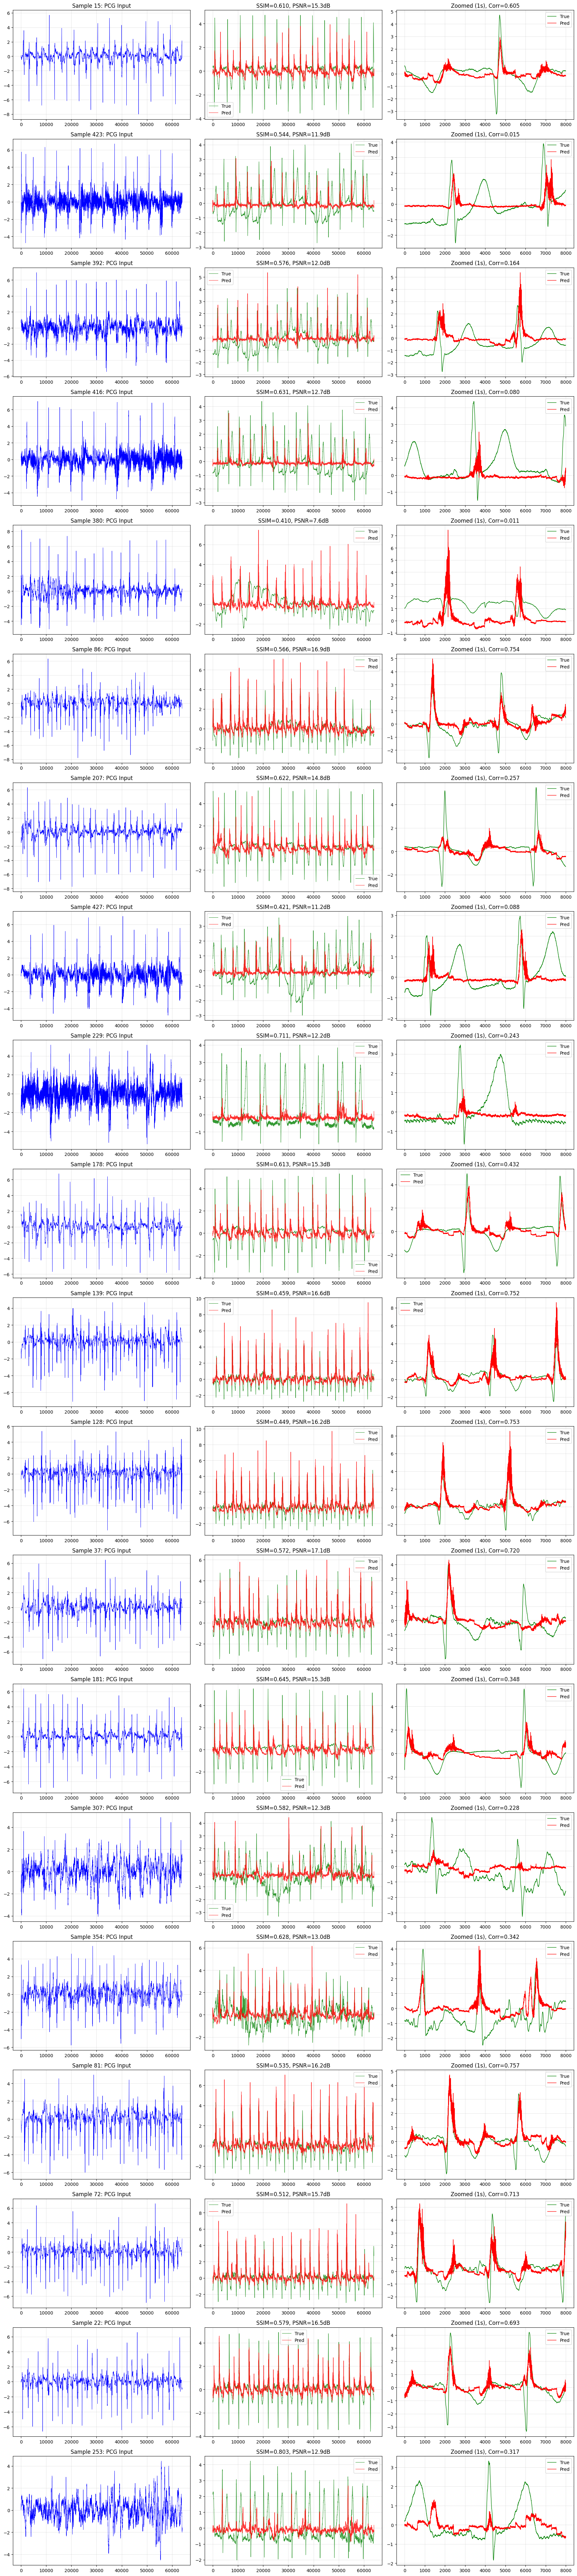

In [27]:
# Visualize sample reconstructions
n_samples = 20
sample_indices = np.random.choice(len(test_predictions), n_samples, replace=False)

fig, axes = plt.subplots(n_samples, 3, figsize=(18, 4*n_samples))

for i, idx in enumerate(sample_indices):
    pcg = test_inputs[idx, 0]
    ecg_true = test_targets[idx, 0]
    ecg_pred = test_predictions[idx, 0]

    # Calculate metrics on-the-fly for this sample
    sample_ssim = calc_ssim(ecg_true, ecg_pred)
    sample_psnr = calc_psnr(ecg_true, ecg_pred)
    sample_corr = calc_correlation(ecg_true, ecg_pred)

    axes[i, 0].plot(pcg, color='blue', linewidth=0.5)
    axes[i, 0].set_title(f'Sample {idx}: PCG Input'); axes[i, 0].grid(True, alpha=0.3)

    axes[i, 1].plot(ecg_true, color='green', linewidth=0.8, label='True', alpha=0.8)
    axes[i, 1].plot(ecg_pred, color='red', linewidth=0.8, label='Pred', alpha=0.8)
    axes[i, 1].set_title(f'SSIM={sample_ssim:.3f}, PSNR={sample_psnr:.1f}dB')
    axes[i, 1].legend(); axes[i, 1].grid(True, alpha=0.3)

    zoom_start = len(ecg_true) // 4
    zoom_end = zoom_start + CONFIG['sample_rate']
    axes[i, 2].plot(ecg_true[zoom_start:zoom_end], color='green', linewidth=1.0, label='True')
    axes[i, 2].plot(ecg_pred[zoom_start:zoom_end], color='red', linewidth=1.0, label='Pred')
    axes[i, 2].set_title(f'Zoomed (1s), Corr={sample_corr:.3f}')
    axes[i, 2].legend(); axes[i, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(model_results_dir, 'sample_reconstructions.png'), dpi=300)
plt.show()

## 9. Summary

In [28]:
print("\n" + "=" * 60)
print("FINAL SUMMARY FOR MODEL COMPARISON")
print("=" * 60)
print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Architecture: Simple CNN Encoder-Decoder (NO skip connections)")
print("-" * 60)
print("KEY METRICS:")
print(f"  SSIM:        {summary_stats['ssim']['mean']:.4f} +/- {summary_stats['ssim']['std']:.4f}")
print(f"  PSNR:        {summary_stats['psnr']['mean']:.2f} +/- {summary_stats['psnr']['std']:.2f} dB")
print(f"  Correlation: {summary_stats['correlation']['mean']:.4f} +/- {summary_stats['correlation']['std']:.4f}")
print("=" * 60)
print("\nThis is a LOWER BOUND baseline. Compare with U-Net to see the")
print("benefit of skip connections.")
print(f"\nNotebook completed! Results saved to: {model_results_dir}")


FINAL SUMMARY FOR MODEL COMPARISON
Model: CNN_EncoderDecoder
Architecture: Simple CNN Encoder-Decoder (NO skip connections)
------------------------------------------------------------
KEY METRICS:
  SSIM:        0.5707 +/- 0.1125
  PSNR:        14.80 +/- 4.65 dB
  Correlation: 0.3701 +/- 0.2807

This is a LOWER BOUND baseline. Compare with U-Net to see the
benefit of skip connections.

Notebook completed! Results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/CNN_EncoderDecoder
